# Question D — When does citation impact emerge, and which papers become “high hitters”?

**Journal:** *Financial Services Review* (FSR)  
**Citation window:** through 2025, the last complete calendar year

This analysis addresses two related questions about research impact in *Financial Services Review*. The first asks **how long it typically takes for a paper to reach its highest observed annual citation count**. The second asks **which observable paper characteristics are associated with becoming a highly cited paper**.

Taken together, the two parts separate **timing** from **predictability**: Part 1 shows when impact tends to become visible, while Part 2 examines whether high-impact papers can be distinguished from the rest using information available in the bibliographic record.

| | Research question | Main method |
|---|---|---|
| **Part 1** | How many years after publication does a paper reach its observed citation peak? | **Kaplan–Meier survival analysis**, followed by a comparison across publication eras |
| **Part 2** | Which paper characteristics are associated with becoming a *high hitter*? | **Logistic regression**, supported by **quantile regression** |


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test
from lifelines.utils import restricted_mean_survival_time

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# --- plotting style (one palette used throughout) ---
BLUE, ORANGE, AQUA, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#52514e"
plt.rcParams.update({
    "figure.figsize": (7.5, 4.5), "figure.dpi": 110,
    "axes.grid": True, "grid.color": "#e6e5e2", "grid.linewidth": 0.8,
    "axes.edgecolor": "#c9c8c4", "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 10, "axes.labelcolor": GREY,
    "text.color": "#0b0b0b", "xtick.color": GREY, "ytick.color": GREY,
    "font.size": 9, "lines.linewidth": 2,
})

LAST_COMPLETE_YEAR = 2025   # 2026 is only partly observed at the data pull (mid-Sept 2026)
JOURNAL = "Financial Services Review"

---
# Part 1 — When do citations peak?

## 1.1 Why this is a survival-analysis problem

A simple approach would be to identify the highest-citation year for every paper and average the corresponding ages. However, this would systematically favour papers whose peaks have already been observed.

For example, a paper published in 2022 has only three complete years of citation history by the end of 2025. If its highest count so far occurs in year 2, that does not necessarily mean year 2 is its eventual peak; the paper may still be gaining attention. Treating that observed maximum as final would therefore make peak ages appear earlier than they really are.

This is a **right-censoring** problem. Kaplan–Meier estimation is useful because papers with incomplete citation histories still contribute information without being forced to have an artificial peak. In practical terms, a censored paper tells us that its peak has **not yet been established within the observed window**.


## 1.2 Notation and estimation

For paper $i = 1, \dots, N$:

| Symbol | Meaning |
|---|---|
| $T_i$ | age at the paper's citation peak — the **event time** |
| $C_i$ | **censoring time** — the maximum age observable by the end of 2025 |
| $X_i = \min(T_i, C_i)$ | the duration recorded in the analysis |
| $\delta_i \in \{0,1\}$ | $1$ if a peak is treated as observed and $0$ if the paper is censored |

Each paper contributes one pair $(X_i, \delta_i)$.

**Operational censoring rule.** A peak is treated as observed only when the maximum annual citation count occurs before the final observable year, so that at least one complete year after that maximum is available. If the maximum occurs in the final observable year, or the paper has no citations, the observation is censored at its current age.

Because citation histories remain open-ended, this rule identifies an **observed peak within the available history** rather than proving that no future year could ever exceed it. The results should therefore be interpreted as estimates of time to an observed citation peak under this rule.

### Kaplan–Meier estimator

Let $t_{(1)} < t_{(2)} < \dots < t_{(k)}$ denote the distinct ages at which a peak is observed. At each $t_{(j)}$:

- $n_j$ is the number of papers still **at risk** immediately before $t_{(j)}$; and
- $d_j$ is the number of papers whose peak is observed at $t_{(j)}$.

The estimated survival function is

$$
\hat S(t) \,=\, \prod_{j\,:\,t_{(j)} \le t} \left(1 - \frac{d_j}{n_j}\right).
$$

In this setting, $\hat S(t)$ represents the estimated probability that a paper has **not yet reached its observed citation peak** by age $t$. The confidence band is based on Greenwood's variance estimator.

### Summary measures

The $p$-th quantile of peak age is read from the Kaplan–Meier curve as

$$
t_p \,=\, \inf\{t : \hat S(t) \le 1-p\}.
$$

The median, for example, is the age by which half of papers are estimated to have peaked.

The unrestricted mean cannot be estimated because the survival curve does not fall to zero. Instead, the analysis reports the **restricted mean survival time (RMST)** up to a horizon $\tau$:

$$
\widehat{\mathrm{RMST}}(\tau) \,=\, \int_0^{\tau} \hat S(t)\,dt.
$$

This can be read as the average estimated peak age within the chosen observation horizon. Because some papers remain unpeaked at the end of the window, the full-horizon RMST is a **lower bound** on the unrestricted mean.


### 1.3 Data preparation

Two datasets are combined:

- `fsr_citations_by_year_openalex.csv` contains annual citation counts for each DOI and citation year.
- `master_dataset.csv` contains one row per paper and provides the complete FSR roster, including papers with no recorded citations.

Four preparation rules are applied before modelling:

1. **Duplicate OpenAlex sources.** The citation file contains two OpenAlex pulls, `openalex` and `openalex_citing_works`. The latter is the broader source, so it is retained to avoid double counting while preserving coverage.
2. **Negative citation ages.** Citation records dated before the recorded publication year are removed because they are inconsistent with the publication-age definition used in this analysis.
3. **Incomplete 2026 data.** The citation window ends at **2025**, the last complete year, so partial 2026 counts do not create an artificial decline.
4. **Zero-citation papers.** Papers with no citing works are retained in the roster and treated as censored rather than being assigned a peak at age 0.

After these rules, the Kaplan–Meier analysis contains **616 papers**: **376 observed peaks (61.0%)** and **240 censored papers (39.0%)**. Retaining the censored papers is important because excluding them would disproportionately remove recent and slow-building research.


In [2]:
cit    = pd.read_csv("fsr_citations_by_year_openalex.csv")
master = pd.read_csv("master_dataset.csv")

# rules 1 & 2 & 3
cit = cit[cit["source"] == "openalex_citing_works"]
cit = cit[(cit["years_since_pub"] >= 0) & (cit["citation_year"] <= LAST_COMPLETE_YEAR)]

# full FSR roster (master_dataset.csv also holds two other journals)
papers = (master[master["source_title"] == JOURNAL]
          .dropna(subset=["doi"]).drop_duplicates("doi")[["doi", "year"]]
          .rename(columns={"year": "pub_year"}))
papers = papers[papers["pub_year"] <= LAST_COMPLETE_YEAR].copy()
papers["current_age"] = LAST_COMPLETE_YEAR - papers["pub_year"]

annual = cit.groupby(["doi", "years_since_pub"])["cites_that_year"].sum()   # (doi, age) -> cites

def peak_and_event(doi, current_age):
    # Return (duration X_i, event indicator delta_i) under the censoring rule in 1.2.
    series = np.array([annual.get((doi, a), 0) for a in range(current_age + 1)])
    if series.sum() == 0:                      # rule 4: never cited -> censored
        return current_age, 0
    peak_age = int(np.argmax(series))          # first max if tied
    if peak_age < current_age:                 # a full year seen after the peak -> event
        return peak_age, 1
    return current_age, 0                      # peak sits on the edge of observation -> censored

papers["peak_age"], papers["peaked"] = zip(*[peak_and_event(r.doi, r.current_age)
                                             for r in papers.itertuples()])
km_df = papers[["doi", "pub_year", "current_age", "peak_age", "peaked"]]

print(f"Papers            : {len(km_df)}")
print(f"Peaks observed    : {km_df['peaked'].sum()}  ({km_df['peaked'].mean():.1%})")
print(f"Right-censored    : {(1 - km_df['peaked']).sum()}  ({1 - km_df['peaked'].mean():.1%})")
km_df.head()

Papers            : 616
Peaks observed    : 376  (61.0%)
Right-censored    : 240  (39.0%)


,doi,pub_year,current_age,peak_age,peaked
0,10.2139/ssrn.3272486,2020,5,5,0
1,10.61190/fsr.v25i2.3218,2016,9,1,1
2,10.61190/fsr.v23i2.3133,2014,11,7,1
3,10.61190/fsr.v32i4.3355,2024,1,1,0
4,10.61190/fsr.v22i4.4661,2013,12,12,0


### 1.4 Estimating the citation-peak curve

The Kaplan–Meier curve below tracks the share of papers that are estimated to have **not yet peaked** at each publication age. A slow decline therefore indicates that citation impact develops over a long period rather than concentrating in the first few years after publication.


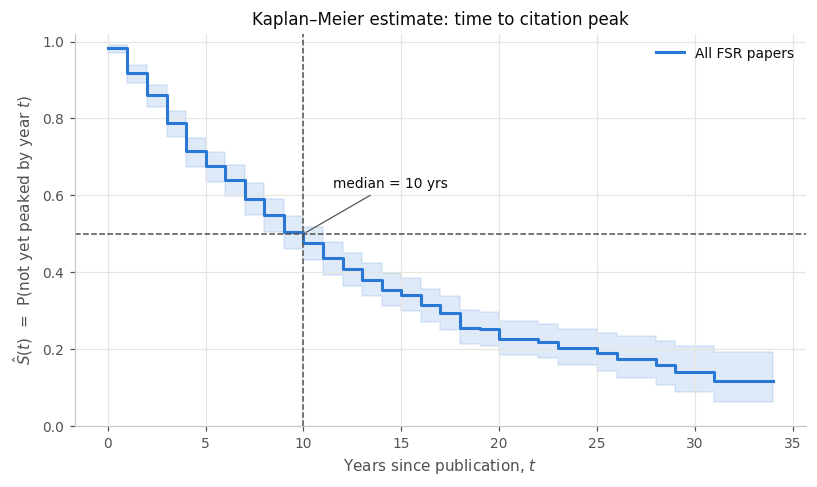

In [3]:
kmf = KaplanMeierFitter().fit(km_df["peak_age"], km_df["peaked"], label="All FSR papers")

ax = kmf.plot_survival_function(ci_show=True, color=BLUE, ci_alpha=0.15)
median = kmf.median_survival_time_
ax.axhline(0.5, color=GREY, ls="--", lw=1)
ax.axvline(median, color=GREY, ls="--", lw=1)
ax.annotate(f"median = {median:.0f} yrs", xy=(median, 0.5), xytext=(median + 1.5, 0.62),
            color="#0b0b0b", fontsize=9,
            arrowprops=dict(arrowstyle="-", color=GREY, lw=0.8))
ax.set_xlabel("Years since publication, $t$")
ax.set_ylabel(r"$\hat{S}(t)$  =  P(not yet peaked by year $t$)")
ax.set_title("Kaplan–Meier estimate: time to citation peak")
ax.set_ylim(0, 1.02)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.show()

### 1.5 How long does it take for citation impact to mature?

The distribution is summarised using the 25th percentile, median, 75th percentile and restricted mean peak age. These measures are useful together: the median describes the typical paper, while the interquartile range shows how widely peak timing varies across the journal.


In [4]:
levels = [0.25, 0.50, 0.75]
quantile_table = pd.DataFrame({
    "quantile p": levels,
    "peak age (years)": kmf.percentile(1 - np.array(levels)).values.ravel(),
    "reading": ["25% of papers have peaked by this age",
                "median: half have peaked by this age",
                "75% have peaked by this age"],
})
display(quantile_table)

tau_max = int(km_df["peak_age"].max())
rmst_table = pd.DataFrame({
    "horizon tau (years)": [10, 20, tau_max],
    "RMST = mean peak age within tau": [restricted_mean_survival_time(kmf, t=t) for t in [10, 20, tau_max]],
})
display(rmst_table)

print(f"Mean peak age (RMST over the full {tau_max}-year window): "
      f"{restricted_mean_survival_time(kmf, t=tau_max):.2f} years")
print(f"Median peak age                                        : {kmf.median_survival_time_:.0f} years")
print(f"Interquartile range                                    : "
      f"{quantile_table['peak age (years)'][0]:.0f} – {quantile_table['peak age (years)'][2]:.0f} years")
print(f"\nS(t) bottoms out at {kmf.survival_function_.iloc[-1, 0]:.2f}, not 0 -> the RMST above is a LOWER bound "
      "on the true mean.")

,quantile p,peak age (years),reading
0,0.250,4.000,25% of papers have peaked by this age
1,0.500,10.000,median: half have peaked by this age
2,0.750,20.000,75% have peaked by this age


,horizon tau (years),RMST = mean peak age within tau
0,10,7.227
1,20,10.741
2,34,13.162


Mean peak age (RMST over the full 34-year window): 13.16 years
Median peak age                                        : 10 years
Interquartile range                                    : 4 – 20 years

S(t) bottoms out at 0.12, not 0 -> the RMST above is a LOWER bound on the true mean.


### 1.6 Has peak timing changed across publication eras?

Citation behaviour may change over time as the research environment changes. More journals, faster digital discovery and broader indexing may allow newer papers to attract attention more quickly than papers published in earlier decades.

To examine this possibility, the FSR roster is divided into three publication eras — the 1990s, 2000s and 2010s onward — and a separate Kaplan–Meier curve is estimated for each group.

The **log-rank test** assesses whether the three peak-age distributions differ overall. Under the null hypothesis, the eras share the same time-to-peak distribution. A small $p$-value therefore provides evidence that citation timing has changed across cohorts.

At each event time $t_{(j)}$, the expected number of events in group $g$ is

$$
E_{gj} \,=\, d_j \frac{n_{gj}}{n_j},
$$

and the overall test compares observed and expected events across the three groups. With three eras, the test has two degrees of freedom.


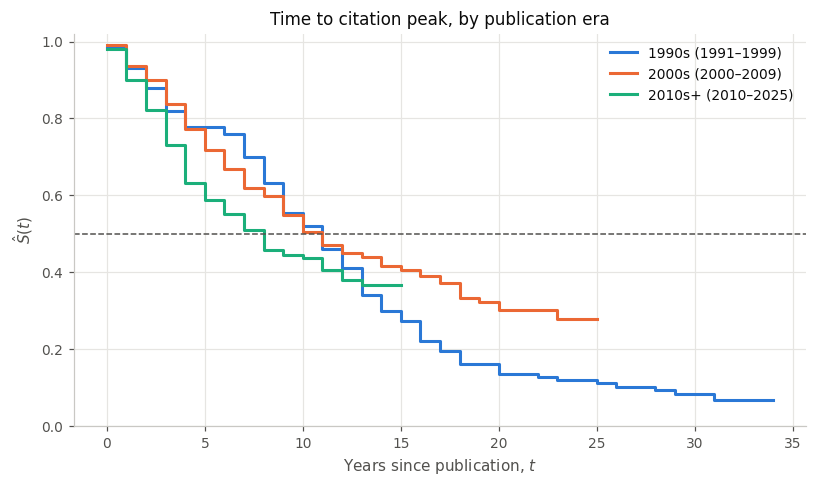

,n papers,censored,median peak age,RMST within 15 yrs
era,,,,
1990s (1991–1999),117,0.077,11.000,9.855
2000s (2000–2009),202,0.327,11.000,9.871
2010s+ (2010–2025),297,0.556,8.000,8.578


Log-rank test across the three eras:  chi2 = 9.84  (df = 2),  p = 0.0073
=> reject H0: the eras do NOT share one peak-age distribution.


In [6]:
def era_of(y):
    if y < 2000:  return "1990s (1991–1999)"
    if y < 2010:  return "2000s (2000–2009)"
    return "2010s+ (2010–2025)"

km_df = km_df.assign(era=km_df["pub_year"].apply(era_of))
ERAS   = ["1990s (1991–1999)", "2000s (2000–2009)", "2010s+ (2010–2025)"]
COLORS = {ERAS[0]: BLUE, ERAS[1]: ORANGE, ERAS[2]: AQUA}

fig, ax = plt.subplots()
rows = []
for era in ERAS:
    g = km_df[km_df["era"] == era]
    k = KaplanMeierFitter().fit(g["peak_age"], g["peaked"], label=era)
    k.plot_survival_function(ax=ax, ci_show=False, color=COLORS[era])
    rows.append({
        "era": era, "n papers": len(g), "censored": 1 - g["peaked"].mean(),
        "median peak age": k.median_survival_time_,
        "RMST within 15 yrs": restricted_mean_survival_time(k, t=15),
    })

ax.axhline(0.5, color=GREY, ls="--", lw=1)
ax.set_xlabel("Years since publication, $t$")
ax.set_ylabel(r"$\hat{S}(t)$")
ax.set_title("Time to citation peak, by publication era")
ax.set_ylim(0, 1.02); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

display(pd.DataFrame(rows).set_index("era"))

lr = multivariate_logrank_test(km_df["peak_age"], km_df["era"], km_df["peaked"])
print(f"Log-rank test across the three eras:  chi2 = {lr.test_statistic:.2f}  "
      f"(df = {len(ERAS) - 1}),  p = {lr.p_value:.4f}")
print("=> reject H0: the eras do NOT share one peak-age distribution." if lr.p_value < 0.05
      else "=> no evidence the eras differ.")

### 1.8 Interpretation — FSR impact develops slowly, although newer papers appear to peak earlier

The Kaplan–Meier results show that citation impact in *Financial Services Review* is generally a **long-cycle process** rather than an immediate one. The estimated median peak age is **10 years**, meaning that half of papers reach their observed citation peak within a decade. The middle 50% of papers peak between **4 and 20 years**, showing substantial variation around that typical value.

The restricted mean peak age over the 34-year observation window is **13.2 years**. Because the survival curve remains above zero at the end of the window, this value is best treated as a **lower bound** rather than a complete lifetime average. In plain language, a meaningful minority of papers are still building citation impact many years after publication.

This has an important implication for performance assessment. Only **13.8%** of papers have peaked by year 2, **21.3%** by year 3, **28.5%** by year 4 and **32.4%** by year 5. Standard short citation windows therefore capture only the early part of the FSR citation life cycle. Judging a paper after two or three years may substantially understate work whose influence develops more gradually.

There is also evidence that this cycle is becoming faster. Median peak age is **11 years** for both the 1990s and 2000s cohorts, compared with **8 years** for papers published from 2010 onward. The difference is statistically significant (log-rank $\chi^2 = 9.84$, $p = 0.007$), and the same ordering remains when the groups are compared over a common 15-year horizon.

However, the newer cohort is also much more heavily censored (**55.6%**, compared with **7.7%** for the 1990s). Kaplan–Meier estimation is designed to accommodate this, but the recent curve is necessarily less mature. The safest conclusion is therefore that **newer FSR papers show evidence of peaking earlier**, while the exact size of that shift should be interpreted cautiously.

**Practical implication.** For editors, researchers or anyone evaluating journal performance, a single short citation window does not tell the whole story. FSR appears to require a longer evaluation horizon — roughly **8–10 years for a typical paper** — alongside early-impact indicators.


---
# Part 2 — What makes a paper a “high hitter”?

## 2.1 Defining the outcome

The second part asks whether highly cited papers can be distinguished from the rest using observable bibliographic characteristics.

A **high hitter** is defined using the 90th-percentile citation threshold. In the modelling sample, this corresponds to papers with **at least 26 citations**. Because several papers are tied at the cutoff, **63 of 582 papers (10.8%)** are classified as high hitters rather than exactly 10%.

This produces a binary outcome, so the main model is a **logistic regression**. Let $H_i = 1$ when paper $i$ is a high hitter. Then

$$
\Pr(H_i = 1 \mid \mathbf{x}_i) \,=\, p_i \,=\, \frac{1}{1 + \exp[-(\beta_0 + \boldsymbol{\beta}^{\top}\mathbf{x}_i)]}.
$$

Equivalently,

$$
\operatorname{logit}(p_i) \,=\, \ln\!\left(\frac{p_i}{1-p_i}\right) \,=\, \beta_0 + \boldsymbol{\beta}^{\top}\mathbf{x}_i.
$$

For each predictor, $\exp(\beta_j)$ is an **odds ratio (OR)**. An OR above 1 indicates higher odds of high-hitter status, while an OR below 1 indicates lower odds, holding the remaining predictors constant.

### Why paper age is included

Older papers have had more time to accumulate citations. Because the high-hitter definition is based on raw citation counts, age must be controlled for before the other characteristics can be interpreted fairly. The model therefore includes $\ln(\text{age})$ as an exposure control. This allows the remaining coefficients to describe associations with high-hitter status **beyond the simple advantage of having been published for longer**.


## 2.2 Paper characteristics considered

The model uses six variables derived from `master_dataset.csv`.

| Feature | Derivation | What it represents in this analysis |
|---|---|---|
| `n_authors` | number of `;`-separated author IDs | team size |
| `n_affiliations` | number of `;`-separated affiliations | institutional spread |
| `n_keywords` | number of author keywords | keyword breadth |
| `page_length` | `page_end − page_start` | article length |
| `abstract_length` | abstract word count | abstract length |
| `log_age` | $\ln(2025 - \text{year})$ | time available to accumulate citations |

Two variables are deliberately excluded. `document_type` contains no useful variation because all FSR records are coded as articles. A separate publication-year term is also excluded because publication year and age contain almost the same information, creating unnecessary multicollinearity when both are included.

Papers with missing page information or citation counts, and papers younger than one complete year, are removed from the modelling sample. This leaves **582 papers** for Part 2.


In [7]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report
from sklearn.model_selection import StratifiedKFold
from scipy import stats

fsr = master[master["source_title"] == JOURNAL].copy()
fsr["n_authors"]       = fsr["authors_id"].str.split(";").str.len()
fsr["n_affiliations"]  = fsr["affiliations"].fillna("").str.split(";").str.len()
fsr["n_keywords"]      = fsr["author_keywords"].fillna("").apply(lambda s: len(s.split(";")) if s else 0)
fsr["page_length"]     = fsr["page_end"] - fsr["page_start"]
fsr["abstract_length"] = fsr["abstract"].fillna("").str.split().str.len()
fsr["age"]             = LAST_COMPLETE_YEAR - fsr["year"]
fsr = fsr[fsr["age"] > 0].dropna(subset=["cited_by", "page_length"]).copy()
fsr["log_age"] = np.log(fsr["age"])

FEATURES = ["log_age", "n_authors", "n_affiliations", "n_keywords", "page_length", "abstract_length"]

# --- the outcome ---
cutoff = fsr["cited_by"].quantile(0.90)
fsr["high_hitter"] = (fsr["cited_by"] >= cutoff).astype(int)

print(f"Papers in model : {len(fsr)}")
print(f"High-hitter cutoff: >= {cutoff:.0f} citations "
      f"({fsr['high_hitter'].sum()} papers, {fsr['high_hitter'].mean():.1%})")
fsr[FEATURES + ["cited_by"]].describe().T[["mean", "std", "min", "50%", "max"]]

Papers in model : 582
High-hitter cutoff: >= 26 citations (63 papers, 10.8%)


,mean,std,min,50%,max
log_age,2.590,0.812,0.000,2.833,3.526
n_authors,2.225,0.920,1.000,2.000,7.000
n_affiliations,1.737,0.824,1.000,2.000,6.000
n_keywords,3.139,1.907,0.000,3.000,11.000
page_length,16.220,5.347,1.000,16.000,41.000
abstract_length,122.660,38.129,3.000,113.000,453.000
cited_by,15.141,43.755,0.000,5.000,678.000


### Why focus on the upper tail?

Before modelling, it is useful to establish whether highly cited papers actually matter to the journal's overall citation profile. If citations were distributed fairly evenly, identifying the top group would have limited practical value. If citations are strongly concentrated, however, a relatively small number of papers can account for a large share of the journal's visibility.


In [8]:
c = fsr["cited_by"].sort_values(ascending=False)
n_top = int(round(0.10 * len(c)))
print("Citation concentration")
print(f"  total citations across {len(c)} papers : {c.sum():,}")
print(f"  top 10% of papers ({n_top}) hold        : {100 * c.head(n_top).sum() / c.sum():.1f}% of all citations")
print(f"  top 1%  of papers ({max(1, len(c)//100)}) hold         : "
      f"{100 * c.head(max(1, len(c)//100)).sum() / c.sum():.1f}%")
print(f"  bottom half hold                      : {100 * c.tail(len(c)//2).sum() / c.sum():.1f}%")
print(f"  papers with zero citations            : {(fsr['cited_by'] == 0).sum()} "
      f"({(fsr['cited_by'] == 0).mean():.1%})")

print("\nAuthor-count mix")
mix = (fsr["n_authors"].value_counts(normalize=True).sort_index() * 100).round(1)
for k, v in mix.items():
    print(f"  {k} author(s): {v:5.1f}%")

Citation concentration
  total citations across 582 papers : 8,812
  top 10% of papers (58) hold        : 63.7% of all citations
  top 1%  of papers (5) hold         : 21.1%
  bottom half hold                      : 5.8%
  papers with zero citations            : 59 (10.1%)

Author-count mix
  1 author(s):  20.8%
  2 author(s):  45.2%
  3 author(s):  27.1%
  4 author(s):   5.3%
  5 author(s):   0.9%
  6 author(s):   0.5%
  7 author(s):   0.2%


The citation distribution is highly concentrated. The top 10% of papers account for **63.7% of all citations**, while the top 1% alone account for **21.1%**. By comparison, the bottom half of papers contribute only **5.8%** of citations.

This concentration makes the high-hitter question practically important: a relatively small group of papers contributes disproportionately to the journal's citation footprint. The next step is therefore to test whether those papers can be recognised from basic bibliographic characteristics.

## 2.3 Logistic regression


In [9]:
X = sm.add_constant(fsr[FEATURES])
y = fsr["high_hitter"]

logit = sm.Logit(y, X).fit(disp=0)
print(logit.summary())

                           Logit Regression Results                           
Dep. Variable:            high_hitter   No. Observations:                  582
Model:                          Logit   Df Residuals:                      575
Method:                           MLE   Df Model:                            6
Date:                Tue, 15 Sep 2026   Pseudo R-squ.:                 0.08961
Time:                        00:46:57   Log-Likelihood:                -181.65
converged:                       True   LL-Null:                       -199.53
Covariance Type:            nonrobust   LLR p-value:                 3.068e-06
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -6.3810      1.782     -3.582      0.000      -9.873      -2.889
log_age             1.4647      0.405      3.618      0.000       0.671       2.258
n_authors           0.4427      

## 2.4 Model diagnostics and assumptions

Before interpreting the coefficients, the model is checked for the main conditions that can make logistic-regression estimates unstable or misleading.

| Diagnostic | Purpose | Guideline used |
|---|---|---|
| **Box–Tidwell test** | checks whether continuous predictors are approximately linear on the log-odds scale | no interaction term significant at $p < 0.05$ |
| **Variance inflation factor (VIF)** | checks for multicollinearity among predictors | VIF below 5 |
| **Cook's distance** | screens for observations with unusually strong influence | inspect values above $4/N$ and the maximum distance |
| **Convergence / separation** | checks whether the logistic model can estimate finite, stable coefficients | successful convergence with finite standard errors |
| **Events per variable (EPV)** | checks whether there are enough high-hitter events relative to the number of predictors | approximately 10 or more events per predictor |

The observations are treated as independent because the modelling dataset contains one row per paper.


In [10]:
# --- 1. Box–Tidwell: is each continuous predictor linear in the logit? ---
continuous = ["n_authors", "n_keywords", "page_length", "abstract_length", "log_age"]
bt = fsr.copy()
for c in continuous:
    pos = bt[c].where(bt[c] > 0, 0.5)          # log needs strictly positive input
    bt[f"bt_{c}"] = pos * np.log(pos)
bt_fit = sm.Logit(bt["high_hitter"], sm.add_constant(bt[FEATURES + [f"bt_{c}" for c in continuous]])).fit(disp=0)
bt_out = pd.DataFrame({"Box–Tidwell p-value": bt_fit.pvalues[[f"bt_{c}" for c in continuous]].values},
                      index=continuous)
bt_out["linear in logit?"] = np.where(bt_out["Box–Tidwell p-value"] > 0.05, "OK", "VIOLATED")

# --- 2. VIF ---
vif = pd.DataFrame({"VIF": [variance_inflation_factor(X.values, i + 1) for i in range(len(FEATURES))]},
                   index=FEATURES)
vif["multicollinearity?"] = np.where(vif["VIF"] < 5, "OK", "PROBLEM")

display(bt_out); display(vif)

# --- 3. Influence ---
cooks = logit.get_influence().cooks_distance[0]
print(f"[3] Influence     : max Cook's D = {cooks.max():.4f}  "
      f"({(cooks > 4/len(fsr)).sum()} points above the 4/N screen of {4/len(fsr):.4f}) "
      f"-> {'OK, no single paper drives the fit' if cooks.max() < 0.5 else 'CHECK'}")

# --- 4. Separation ---
print(f"[4] Separation    : converged = {logit.mle_retvals['converged']}, "
      f"max |coef| = {logit.params.abs().max():.2f}, max SE = {logit.bse.max():.2f} -> OK")

# --- 5. Events per variable ---
epv = y.sum() / len(FEATURES)
print(f"[5] EPV           : {y.sum()} events / {len(FEATURES)} predictors = {epv:.1f} "
      f"-> {'OK (>= 10)' if epv >= 10 else 'BORDERLINE (< 10): treat marginal p-values cautiously'}")

# --- overall fit ---
print(f"\nModel fit         : pseudo R^2 = {logit.prsquared:.3f}, "
      f"LR test vs intercept-only chi2 = {logit.llr:.1f}, p = {logit.llr_pvalue:.2e}")

,Box–Tidwell p-value,linear in logit?
n_authors,0.138,OK
n_keywords,0.745,OK
page_length,0.565,OK
abstract_length,0.300,OK
log_age,0.096,OK


,VIF,multicollinearity?
log_age,1.421,OK
n_authors,1.680,OK
n_affiliations,1.625,OK
n_keywords,1.171,OK
page_length,1.249,OK
abstract_length,1.121,OK


[3] Influence     : max Cook's D = 0.0458  (52 points above the 4/N screen of 0.0069) -> OK, no single paper drives the fit
[4] Separation    : converged = True, max |coef| = 6.38, max SE = 1.78 -> OK
[5] EPV           : 63 events / 6 predictors = 10.5 -> OK (>= 10)

Model fit         : pseudo R^2 = 0.090, LR test vs intercept-only chi2 = 35.8, p = 3.07e-06


**Diagnostic assessment.** Overall, the diagnostics support using the model, but they also suggest some restraint around borderline findings. The Box–Tidwell tests do not provide evidence of important non-linearity, and all VIF values are below **1.7**, indicating that severe multicollinearity is not present after the redundant calendar-year term is removed.

The model converges normally and does not show signs of separation. The maximum Cook's distance is modest (**0.046**), so no single paper appears to dominate the fit, although **52 observations exceed the conservative $4/N$ screening threshold** and could be examined in a formal sensitivity analysis if stronger causal or inferential claims were required.

The main limitation is sample size in the positive class. With **63 high hitters and six predictors**, EPV is **10.5**, only slightly above the conventional rule-of-thumb threshold. Results with $p$-values near 0.05–0.10 are therefore treated as **suggestive rather than conclusive**.


## 2.5 Which characteristics are associated with high-hitter status?

The coefficient table and forest plot below show the estimated odds ratios and 95% confidence intervals. The most useful reading is not simply whether an odds ratio is above or below 1, but whether the effect is **large enough and precise enough** to distinguish a reliable pattern from sampling uncertainty.


In [11]:
ci = logit.conf_int().loc[FEATURES]
sd = fsr[FEATURES].std()

results = pd.DataFrame({
    "coef (log-odds)": logit.params[FEATURES],
    "odds ratio":      np.exp(logit.params[FEATURES]),
    "OR CI low":       np.exp(ci[0]),
    "OR CI high":      np.exp(ci[1]),
    "OR per +1 SD":    np.exp(logit.params[FEATURES] * sd),   # comparable across variables
    "p-value":         logit.pvalues[FEATURES],
}).sort_values("p-value")
display(results)

,coef (log-odds),odds ratio,OR CI low,OR CI high,OR per +1 SD,p-value
log_age,1.465,4.326,1.957,9.565,3.284,0.000
n_authors,0.443,1.557,1.105,2.194,1.503,0.011
n_affiliations,-0.356,0.700,0.466,1.052,0.745,0.086
abstract_length,-0.009,0.991,0.980,1.002,0.707,0.095
page_length,0.046,1.047,0.986,1.112,1.279,0.135
n_keywords,0.025,1.025,0.869,1.209,1.048,0.769


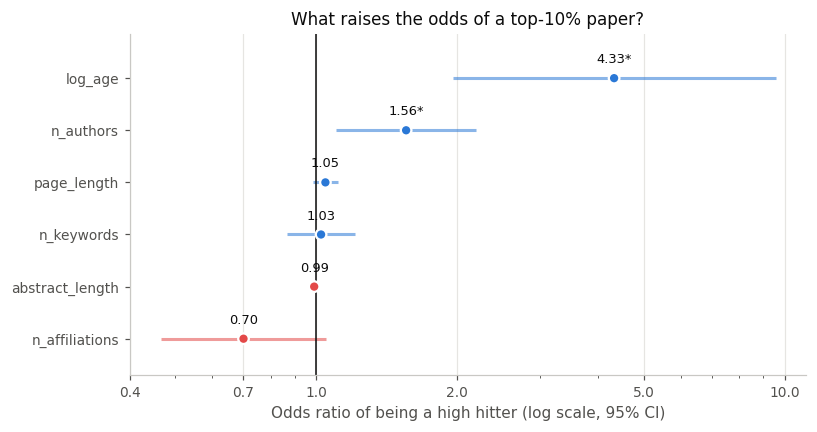

* p < 0.05.   Blue = raises the odds, red = lowers them.


In [12]:
# Forest plot of odds ratios (log scale, so OR and 1/OR are symmetric about 1)
plot_df = results.sort_values("odds ratio")
pos = np.arange(len(plot_df))
colors = [BLUE if o > 1 else RED for o in plot_df["odds ratio"]]

fig, ax = plt.subplots(figsize=(7.5, 4.0))
ax.hlines(pos, plot_df["OR CI low"], plot_df["OR CI high"], color=colors, lw=2, alpha=0.55)
ax.scatter(plot_df["odds ratio"], pos, color=colors, s=48, zorder=3,
           edgecolor="white", linewidth=1.5)
ax.axvline(1, color="#0b0b0b", lw=1)
ax.set_yticks(pos); ax.set_yticklabels(plot_df.index)
ax.set_ylim(-0.7, len(plot_df) - 0.15)
ax.set_xscale("log")
ax.set_xticks([0.4, 0.7, 1, 2, 5, 10])
ax.get_xaxis().set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
ax.get_xaxis().set_minor_formatter(plt.matplotlib.ticker.NullFormatter())
ax.set_xlabel("Odds ratio of being a high hitter (log scale, 95% CI)")
ax.set_title("What raises the odds of a top-10% paper?")
ax.grid(axis="y", visible=False)
for i, (o, pv) in enumerate(zip(plot_df["odds ratio"], plot_df["p-value"])):
    ax.annotate(f"{o:.2f}{'*' if pv < 0.05 else ''}", (o, i), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=8.5, color="#0b0b0b")
plt.tight_layout(); plt.show()
print("* p < 0.05.   Blue = raises the odds, red = lowers them.")

### Interpretation

Two variables stand out most clearly in the logistic model. First, paper age is strongly associated with high-hitter status, which is expected because older papers have had more time to accumulate citations. This is an exposure effect rather than evidence that age makes a paper intrinsically better.

Second, **author count is the only paper characteristic with a statistically clear association after controlling for age**. Each additional author is associated with **1.56 times the odds** of being a high hitter (95% CI 1.10–2.19, $p = 0.011$).

The remaining characteristics are much less certain. Affiliations and abstract length have negative estimated associations, while page length has a positive estimate, but their confidence intervals include no effect. Keyword count shows almost no relationship with high-hitter status.

Odds ratios can still feel abstract, so the next table converts the author-count result into predicted probabilities while holding the other characteristics at their sample averages.


In [13]:
baseline = fsr[FEATURES].mean()
rows = []
for k in [1, 2, 3]:
    r = baseline.copy(); r["n_authors"] = k
    p_k = logit.predict(sm.add_constant(pd.DataFrame([r])[FEATURES], has_constant="add"))[0]
    rows.append({"authors": k, "P(top decile) at mean age": p_k})
    r["log_age"] = np.log(20)
    rows[-1]["P(top decile) at age 20"] = logit.predict(
        sm.add_constant(pd.DataFrame([r])[FEATURES], has_constant="add"))[0]
display(pd.DataFrame(rows).set_index("authors").style.format("{:.1%}"))

,P(top decile) at mean age,P(top decile) at age 20
authors,,
1,4.5%,7.9%
2,6.8%,11.7%
3,10.3%,17.2%


For an otherwise average paper, the model estimates a **4.5%** probability of high-hitter status with one author, **6.8%** with two authors and **10.3%** with three authors. For a 20-year-old paper, the corresponding estimates are **7.9%**, **11.7%** and **17.2%**.

These numbers make the pattern easier to interpret: larger author teams are associated with a higher probability of reaching the upper citation tail. However, the result is **associational, not causal**. The model does not show that adding an author will itself create a highly cited paper; team size may also reflect other unmeasured features of the research.

### How well can the model actually identify high hitters?

A statistically significant association is not the same as strong predictive performance. To assess whether these variables are useful for identifying individual high-hitter papers, the model is evaluated using the area under the ROC curve (AUC), cross-validation and classification performance at a threshold matched to the approximate high-hitter rate.


AUC (in-sample)            : 0.712
AUC (5-fold CV)            : 0.687  (+/- 0.053)
AUC (age-only benchmark)   : 0.662
Characteristics add beyond age: LR chi2 = 10.8 (df = 5), p = 0.0561

Confusion matrix at the 90th-percentile threshold:


,pred: normal,pred: high hitter
actual: normal,473,46
actual: high hitter,50,13


              precision    recall  f1-score   support

      normal       0.90      0.91      0.91       519
 high hitter       0.22      0.21      0.21        63

    accuracy                           0.84       582
   macro avg       0.56      0.56      0.56       582
weighted avg       0.83      0.84      0.83       582



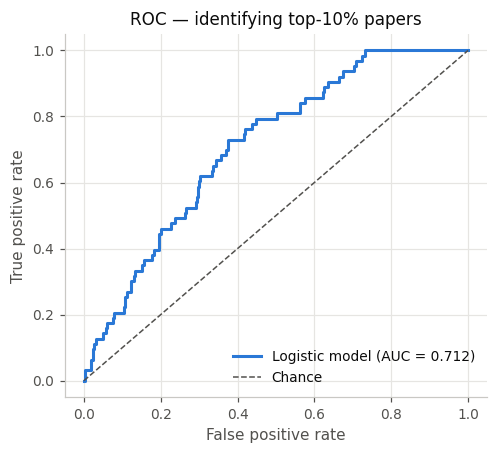

In [14]:
p_hat = logit.predict(X)
auc = roc_auc_score(y, p_hat)

# cross-validated AUC: does it hold up out-of-sample?
cv_aucs = []
for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(X, y):
    f = sm.Logit(y.iloc[tr], X.iloc[tr]).fit(disp=0)
    cv_aucs.append(roc_auc_score(y.iloc[te], f.predict(X.iloc[te])))

# age-only benchmark: how much do the paper characteristics add beyond exposure?
age_only = sm.Logit(y, sm.add_constant(fsr[["log_age"]])).fit(disp=0)
lr_stat = 2 * (logit.llf - age_only.llf)
lr_p = stats.chi2.sf(lr_stat, len(FEATURES) - 1)

print(f"AUC (in-sample)            : {auc:.3f}")
print(f"AUC (5-fold CV)            : {np.mean(cv_aucs):.3f}  (+/- {np.std(cv_aucs):.3f})")
print(f"AUC (age-only benchmark)   : {roc_auc_score(y, age_only.predict(sm.add_constant(fsr[['log_age']]))):.3f}")
print(f"Characteristics add beyond age: LR chi2 = {lr_stat:.1f} (df = {len(FEATURES)-1}), p = {lr_p:.4f}")

# Classification at a threshold matched to the 10% base rate.
# A flat 0.5 cutoff would predict almost nobody a high hitter under a 90/10 split.
pred = (p_hat >= p_hat.quantile(0.90)).astype(int)
cm = confusion_matrix(y, pred)
print("\nConfusion matrix at the 90th-percentile threshold:")
display(pd.DataFrame(cm, index=["actual: normal", "actual: high hitter"],
                        columns=["pred: normal", "pred: high hitter"]))
print(classification_report(y, pred, target_names=["normal", "high hitter"], digits=2))

fpr, tpr, _ = roc_curve(y, p_hat)
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot(fpr, tpr, color=BLUE, label=f"Logistic model (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="Chance")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC — identifying top-10% papers"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

## 2.6 Interpretation — there is a signal, but not a reliable formula for picking winners

The model tells a clear but limited story. **Team size is the strongest observable paper-level signal in the dataset.** After controlling for age, each additional author is associated with 56% higher odds of high-hitter status. This result is statistically significant and remains consistent with the supporting quantile analysis below.

Age has an even larger coefficient, but its interpretation is different. A one-unit increase in $\ln(\text{age})$ multiplies the odds by about **4.33**; equivalently, doubling a paper's age is associated with roughly **2.8 times the odds** of clearing the raw-citation high-hitter threshold. This mainly reflects the extra time available to accumulate citations and is therefore a necessary control rather than an editorial lever.

The evidence for the other metadata variables is weak. More affiliations and longer abstracts are associated with lower odds, and longer papers with higher odds, but none of these effects is statistically conclusive at the 5% level. Keyword count is essentially unrelated to high-hitter status. These variables should therefore **not** be presented as established characteristics of high-impact papers.

The predictive results are even more important for interpretation. The model achieves an AUC of **0.712 in-sample** and **0.687 under five-fold cross-validation**, compared with **0.662 for age alone**. This is better than chance, but only modestly so. At the threshold used to flag roughly the top 10% of predicted papers, the model identifies just **13 of the 63 actual high hitters**.

In practical terms, basic bibliographic metadata can indicate **directional tendencies**, but it cannot reliably identify which individual paper will become a breakout success. Important determinants of future citation impact are therefore likely to lie in information that is **not represented by these variables**.

**Implication for decision-making.** Author-team size may be useful as one descriptive signal when studying citation impact, but it should not be used as a rule for judging submissions or allocating editorial attention. The model is much better suited to explaining broad patterns than to selecting future “winners”.


## 2.7 Supporting analysis — does the relationship change at the top of the citation distribution?

The logistic model reduces citation impact to a yes/no outcome: a paper is either above or below the high-hitter threshold. That is useful for answering the main question, but it does not show whether a characteristic has the same relationship with citations across the whole distribution.

**Quantile regression** provides this additional perspective. Instead of modelling the average outcome, it estimates the relationship separately at different points of the citation distribution. Here the outcome is $\ln(1+\text{citations})$ and the model is estimated at $\tau = 0.10, 0.25, 0.50, 0.75$ and $0.90$.

$$
\hat{\boldsymbol{\beta}}(\tau) \,=\, \arg\min_{\boldsymbol{\beta}} \sum_{i=1}^{N} \rho_\tau\!\left(y_i - \mathbf{x}_i^{\top}\boldsymbol{\beta}\right),
$$

where $\rho_\tau$ is the quantile-regression check function.

The interpretation is straightforward. A relatively flat coefficient path suggests that a characteristic has a similar association across low-, middle- and high-citation papers. A coefficient that becomes larger toward $\tau=0.90$ suggests that the association may be stronger in the upper citation tail.

This supporting analysis is used to **check the pattern**, not to replace the logistic model. In particular, differences between quantile coefficients are described cautiously because the notebook does not conduct a separate formal test of coefficient equality across quantiles.


In [15]:
fsr["log1p_cited"] = np.log1p(fsr["cited_by"])
formula = "log1p_cited ~ " + " + ".join(FEATURES)
TAUS = [0.1, 0.25, 0.5, 0.75, 0.9]

qr = {t: smf.quantreg(formula, fsr).fit(q=t) for t in TAUS}
coefs = pd.DataFrame({f"tau={t}": qr[t].params for t in TAUS}).drop(index="Intercept")
pvals = pd.DataFrame({f"tau={t}": qr[t].pvalues for t in TAUS}).drop(index="Intercept")

print("Coefficients on log(1 + citations) at each quantile:")
display(coefs)
print("\np-values (bold-equivalent: * marks p < 0.05):")
flagged = pvals.map(lambda v: f"{v:.3f}") + np.where(pvals < 0.05, " *", "")
display(flagged)

shift = (coefs["tau=0.9"] - coefs["tau=0.5"]).sort_values(key=abs, ascending=False)
print("Largest median -> tail shift:")
display(shift.to_frame("beta(0.9) - beta(0.5)"))

Coefficients on log(1 + citations) at each quantile:


,tau=0.1,tau=0.25,tau=0.5,tau=0.75,tau=0.9
log_age,0.441,0.411,0.443,0.686,0.822
n_authors,0.175,0.179,0.173,0.186,0.276
n_affiliations,-0.128,-0.028,-0.067,-0.098,-0.170
n_keywords,0.034,0.037,0.029,0.005,0.025
page_length,0.009,0.013,0.007,0.019,0.020
abstract_length,-0.002,-0.001,-0.002,-0.001,-0.002



p-values (bold-equivalent: * marks p < 0.05):


,tau=0.1,tau=0.25,tau=0.5,tau=0.75,tau=0.9
log_age,0.000 *,0.000 *,0.000 *,0.000 *,0.000 *
n_authors,0.064,0.040 *,0.040 *,0.035 *,0.031 *
n_affiliations,0.198,0.762,0.469,0.291,0.167
n_keywords,0.223,0.234,0.386,0.895,0.591
page_length,0.406,0.300,0.574,0.154,0.228
abstract_length,0.293,0.355,0.215,0.661,0.556


Largest median -> tail shift:


,beta(0.9) - beta(0.5)
log_age,0.379
n_affiliations,-0.104
n_authors,0.103
page_length,0.013
n_keywords,-0.004
abstract_length,0.000


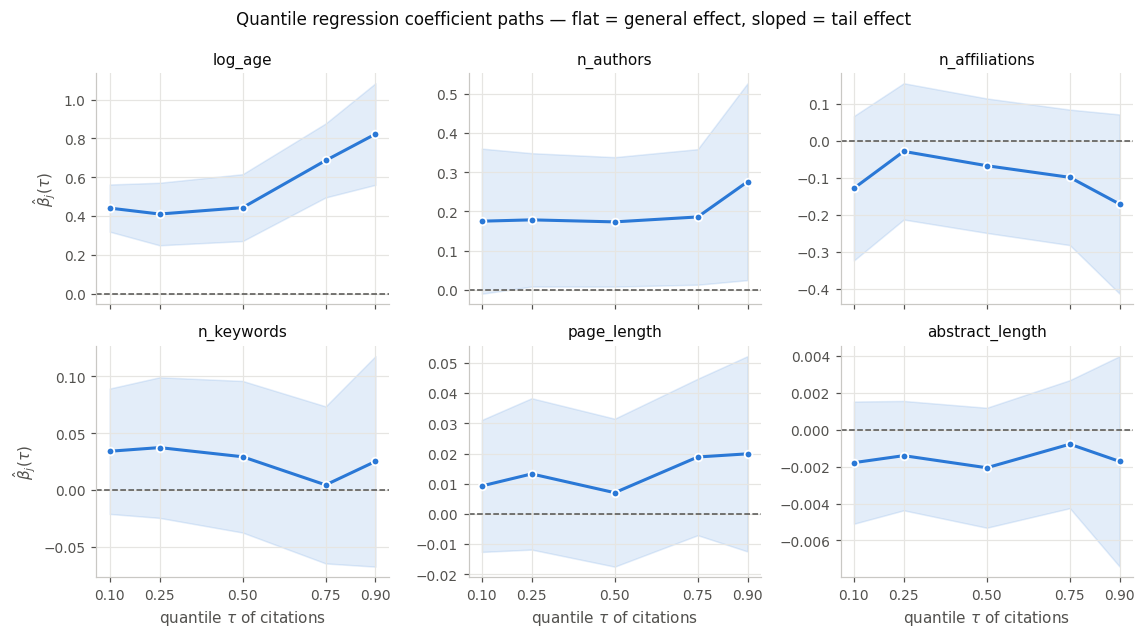

In [16]:
# Coefficient paths: how each characteristic's effect changes across the citation distribution
# Small multiples of the same quantity -> one colour; the panel title carries identity.
fig, axes = plt.subplots(2, 3, figsize=(10.5, 5.8), sharex=True)

for ax, feat in zip(axes.ravel(), FEATURES):
    color = BLUE
    b  = coefs.loc[feat].values
    lo = np.array([qr[t].conf_int().loc[feat, 0] for t in TAUS])
    hi = np.array([qr[t].conf_int().loc[feat, 1] for t in TAUS])
    ax.fill_between(TAUS, lo, hi, color=color, alpha=0.13)
    ax.plot(TAUS, b, color=color, marker="o", markersize=5,
            markeredgecolor="white", markeredgewidth=1.2)
    ax.axhline(0, color=GREY, ls="--", lw=1)
    ax.set_title(feat, fontsize=10)
    ax.set_xticks(TAUS)

for ax in axes[1]:
    ax.set_xlabel(r"quantile $\tau$ of citations")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$\hat{\beta}_j(\tau)$")

fig.suptitle("Quantile regression coefficient paths — flat = general effect, sloped = tail effect",
             fontsize=11, y=0.99)
plt.tight_layout(); plt.show()

### What the quantile regression adds

The quantile paths broadly reinforce the logistic-regression story.

**Author count shows the clearest upper-tail pattern.** Its coefficient is fairly stable at approximately **0.17–0.19** from the lower quantiles through $\tau=0.75$, then increases to **0.276 at $\tau=0.90$**. The coefficient is statistically significant from the 25th percentile upward. This pattern suggests that the association between team size and citations may become stronger among highly cited papers, which is consistent with the positive logistic-regression result.

**Age also becomes more strongly associated with citations toward the upper tail.** The coefficient is around **0.41–0.44** through the median, then rises to **0.69 at $\tau=0.75$** and **0.82 at $\tau=0.90$**. This fits the broader finding from Part 1: citation impact often takes years to mature, so older papers have had more opportunity to move into the high-citation tail.

For **page length** and **institutional spread**, the coefficient paths move in the same directions as the logistic model — positive for page length and negative for affiliations — but these estimates are not statistically significant at the individual quantiles. They should therefore be treated as descriptive patterns rather than established effects.

**Keyword count and abstract length remain weak across the distribution.** Neither shows a consistent, statistically supported relationship with citation performance.

Taken together, the two modelling approaches point to the same main conclusion: **team size is the most consistent paper-level characteristic associated with stronger citation performance after controlling for age**, while most other basic metadata variables add little explanatory power. The upper-tail pattern is suggestive, but it does not turn these variables into a reliable forecasting tool.


---
# Final interpretation and implications

The two parts of the analysis tell one connected story. Citation impact in *Financial Services Review* tends to develop **slowly**, and the papers that eventually dominate the citation distribution are **difficult to identify in advance from basic metadata alone**.

## 1. Citation impact takes time to become visible

| Measure | Estimate |
|---|---:|
| Median observed peak age | **10 years** |
| Interquartile range | **4–20 years** |
| RMST over the 34-year horizon | **13.2 years** (lower bound) |
| Median by era: 1990s / 2000s / 2010s+ | **11 / 11 / 8 years** |
| Log-rank test across eras | $p = 0.007$ |

Only about **14%** of papers have peaked by year 2 and **32%** by year 5. For FSR, short citation windows therefore describe early momentum rather than mature influence. The evidence also suggests that newer papers are reaching their observed peak somewhat faster, although the recent cohort is more heavily censored and should be interpreted with caution.

## 2. High-impact papers are concentrated, but only partly predictable

The top 10% of papers account for **63.7% of all citations**, so high hitters matter disproportionately to the journal's overall citation footprint. Yet the modelling results show that their success cannot be reduced to a simple bibliographic formula.

| Characteristic | Main result | Interpretation |
|---|---|---|
| `n_authors` | OR **1.56** (95% CI 1.10–2.19), $p=0.011$ | clearest paper-level association; upper-tail pattern is stronger in the quantile analysis |
| `log_age` | OR **4.33** (95% CI 1.96–9.56) | strong exposure effect; older papers have had more time to accumulate citations |
| `n_affiliations` | OR 0.70, $p=0.086$ | suggestive negative association, not conclusive |
| `abstract_length` | OR 0.99 per word, $p=0.095$ | suggestive negative association, not conclusive |
| `page_length` | OR 1.05 per page, $p=0.135$ | positive direction, but uncertain |
| `n_keywords` | OR 1.03, $p=0.769$ | no meaningful evidence of association |

The model's five-fold cross-validated AUC is **0.687**, and it identifies only **13 of 63** actual high hitters at the selected threshold. This means the available metadata are useful for describing broad patterns, but not for confidently predicting individual breakout papers.

## What this means in practice

For **journal performance measurement**, FSR should be viewed as a long-horizon citation environment. Evaluating papers only through two- to five-year citation windows risks understating research whose influence builds gradually. Longer cohort tracking can provide a more complete view of impact.

For **editorial or research strategy**, collaboration is the clearest observable signal in this dataset, but it should be treated as an association rather than a recipe for success. The analysis does not support using keyword count, article length or abstract length as simple levers for producing highly cited work.

For **future forecasting**, the main opportunity is to move beyond basic metadata. Since the present model has only modest predictive power, richer information would be needed to explain why some papers become exceptional. Potential extensions could examine topic, novelty, author or institutional networks, research design, or early citation trajectories, provided those variables can be measured consistently.

**Overall conclusion:** FSR's citation impact is both **long-cycle and highly concentrated**. Papers often need many years to reveal their full influence, and although larger author teams are associated with stronger citation performance, the eventual high hitters cannot be reliably identified from the bibliographic characteristics available here alone.
